\begin{align*}
\text{Парамтры моделирования}
\end{align*}


In [61]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import py_files.config as cfg

from py_files.functions import (
                       get_tau_array,
                       get_covariation_matrix,
                       get_channel_matrix,
                       get_barlet_values,
                       get_sin_signal,
                       get_impulse_signal, get_noise, calculate_noise_level, calculate_energy,get_gamma_array, get_avp_signals, get_direction_matrix, get_est_phi
                    
                       
                       )

q = cfg.CONFIG_PARAMETRS
cfg.init_rng()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


{'snr': 2,
 'M': 3,
 'time_vector': array([-8.67361738e-19,  1.13636364e-04,  2.27272727e-04, ...,
         1.13602273e+00,  1.13613636e+00,  1.13625000e+00], shape=(10000,)),
 'duration_all': np.float64(1.13625),
 'N': 10000,
 'R': 1.7163,
 'f0': 10,
 'A': 1,
 'c': 343.26,
 'duration_pulse': 0.01,
 'realisation_count': 100,
 'target_phi': 1.5707963267948966,
 'alpha': 10,
 'phis': array([0.00000000e+00, 1.00002949e-03, 2.00005899e-03, ...,
        6.28018522e+00, 6.28118525e+00, 6.28218528e+00], shape=(6283,)),
 'main_seed': 10,
 'main_rng': Generator(PCG64) at 0x19D81B6D540,
 'center_pulse': np.float64(0.568125)}

\begin{align*}
\frac{\lambda}{2R} \ge 10 &\implies \lambda \ge 20R \\
\lambda = \frac{c}{f} &\implies \frac{c}{f} \ge 20R \implies f_{\text{max}} \le \frac{c}{20R} \\
\text{При } R = 1\text{ м:} \quad f_{\text{max}} &= \frac{343{,}26}{20 \cdot 1} \approx 17{,}16 \text{ Гц}
\end{align*}


\begin{align*}
\text{Сигнал } P(t) \text{ (без шума)}
\end{align*}


In [62]:
values_sin_signal = get_sin_signal(q)
tau = 0.02
values_signal = get_impulse_signal(q)
en_signal = calculate_energy(values_signal, cfg.time_vector)
f_impulse = np.fft.fftshift(np.fft.fft(values_signal))


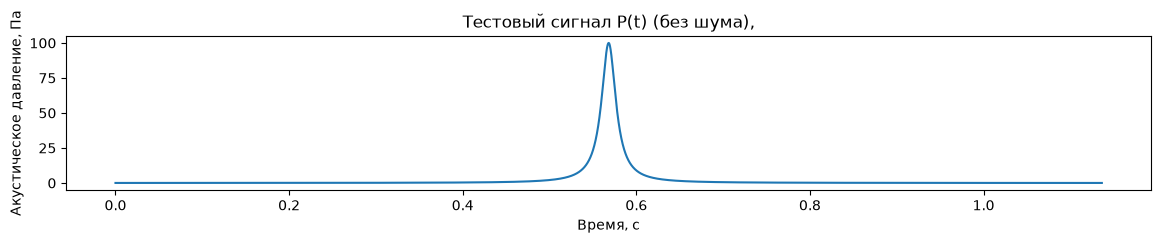

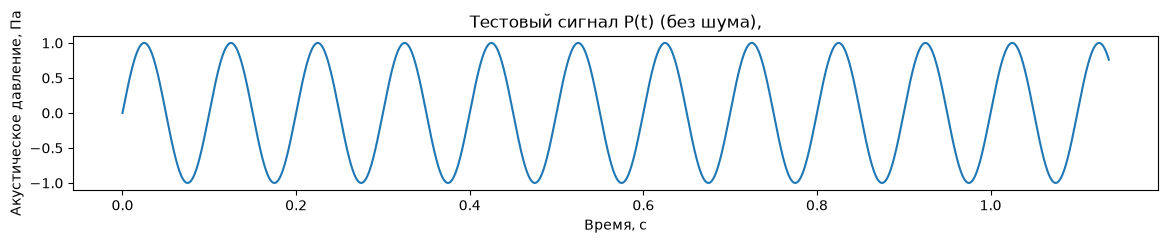

In [63]:
fig, ax = plt.subplots(1,1,figsize = (14,2))
ax.plot(cfg.time_vector, values_signal)


ax.set_xlabel("Время, с")
ax.set_ylabel("Акустическое давление, Па")
ax.set_title("Тестовый сигнал P(t) (без шума),")
plt.show()
fig, ax = plt.subplots(1,1,figsize = (14,2))

ax.plot(cfg.time_vector, values_sin_signal)


ax.set_xlabel("Время, с")
ax.set_ylabel("Акустическое давление, Па")

ax.set_title("Тестовый сигнал P(t) (без шума),")
plt.show()

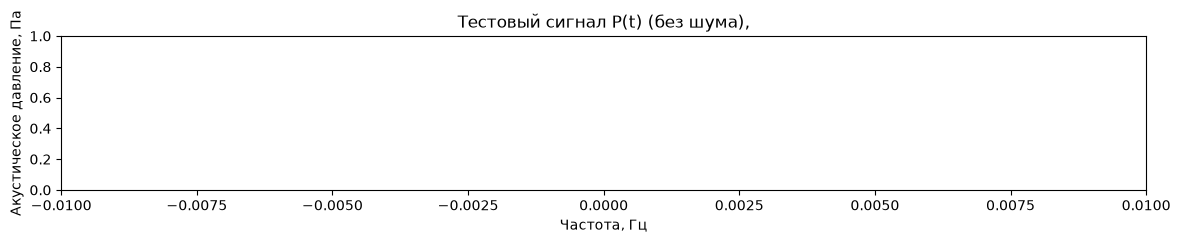

In [64]:
fig, ax = plt.subplots(1,1,figsize = (14,2))
#ax.plot(f_vector, f_impulse)


ax.set_xlabel("Частота, Гц")
ax.set_ylabel("Акустическое давление, Па")
ax.set_xlim(-1e-2,1e-2)
ax.set_title("Тестовый сигнал P(t) (без шума),")
plt.show()

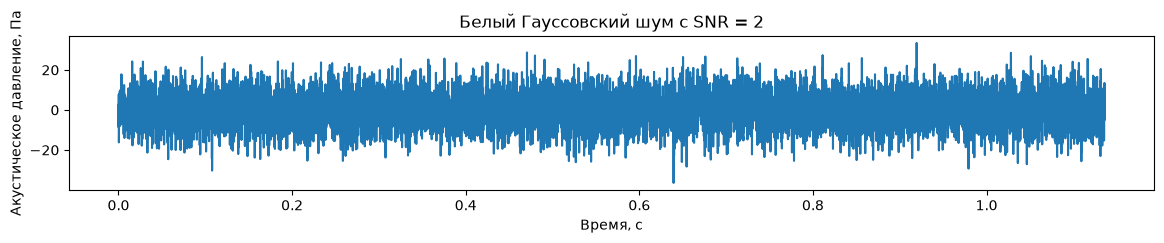

In [65]:
# ШУМ

noise = get_noise(q, np.random.default_rng(42),en_signal)
noise_level = calculate_noise_level(en_signal,cfg.SNR, cfg.DURATION_ALL)
fig, ax = plt.subplots(1,1,figsize = (14,2))
ax.plot(cfg.time_vector, noise)
ax.set_xlabel("Время, с")
ax.set_ylabel("Акустическое давление, Па")
ax.set_title(rf"Белый Гауссовский шум с SNR = {cfg.SNR}")
plt.show()

\begin{align*}
P(t) + e_p(t) \\
\text{С/Ш = 20}
\end{align*} 



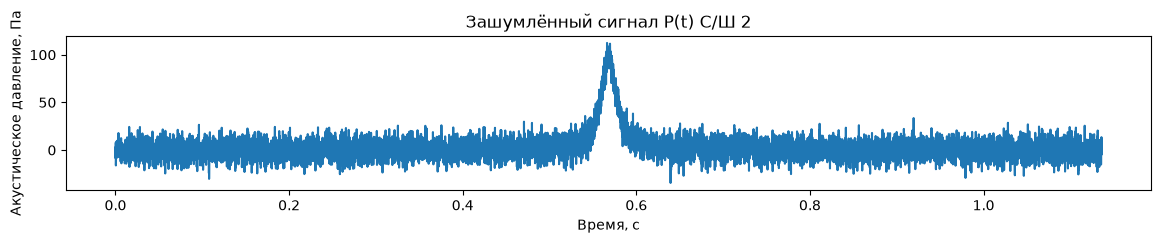

In [66]:
# Построение графика
noise_signal = values_signal + noise
fig, ax = plt.subplots(1,1,figsize = (14,2))
ax.plot(cfg.time_vector, noise_signal)
ax.set_xlabel("Время, с")
ax.set_ylabel("Акустическое давление, Па")
ax.set_title(rf"Зашумлённый сигнал P(t) C/Ш {cfg.SNR}")
plt.show()

Text(0.5, 1.0, 'Сигналы $P(t-\\tau_m)$ для всех АВП')

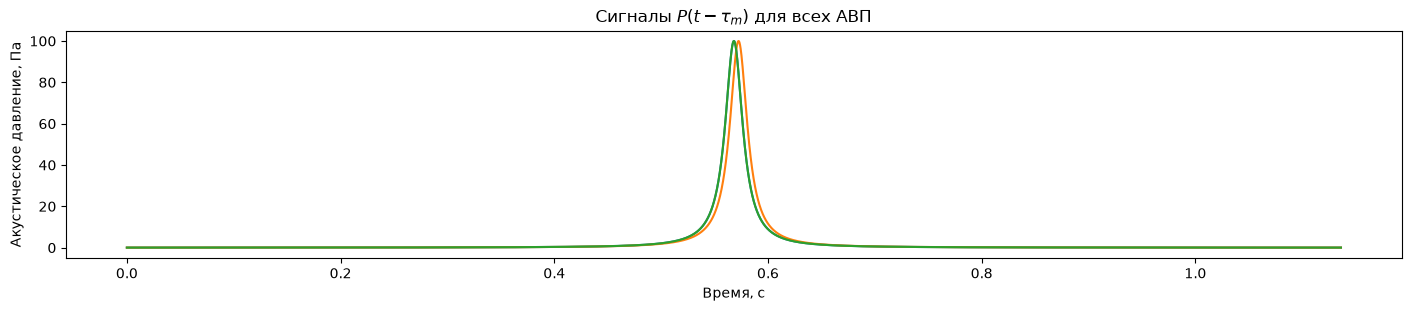

In [67]:
tau_array = get_tau_array(q)
gamma_array = get_gamma_array(cfg.M)
fig, ax = plt.subplots(1,1,figsize = (14,3),constrained_layout = True)

for idx, (tau, gamma) in enumerate(zip(tau_array, gamma_array)):
    q["time_vector"] = q["time_vector"] - tau
    signal = get_impulse_signal(q)
    ax.plot(cfg.time_vector, signal)
    ax.set_xlabel("Время, с")
    ax.set_ylabel("Акустическое давление, Па")
    
    ax.set_title("Сигналы на выходе датчиков решётки с учётом временных задержек")

ax.set_title(r"Сигналы $P(t-\tau_m)$ для всех АВП")

$$
\begin{aligned}
y_0(t) &= P(t) + e_p(t), \\
y_1(t) &= P(t)\cos\varphi_0 + e_1(t), & y_1(t) &= z y_{x_1}(t), & e_1(t) &= z e_{x_1}(t), \\
y_2(t) &= P(t)\sin\varphi_0 + e_2(t), & y_2(t) &= z y_{x_2}(t), & e_2(t) &= z e_{x_2}(t).
\end{aligned}
$$

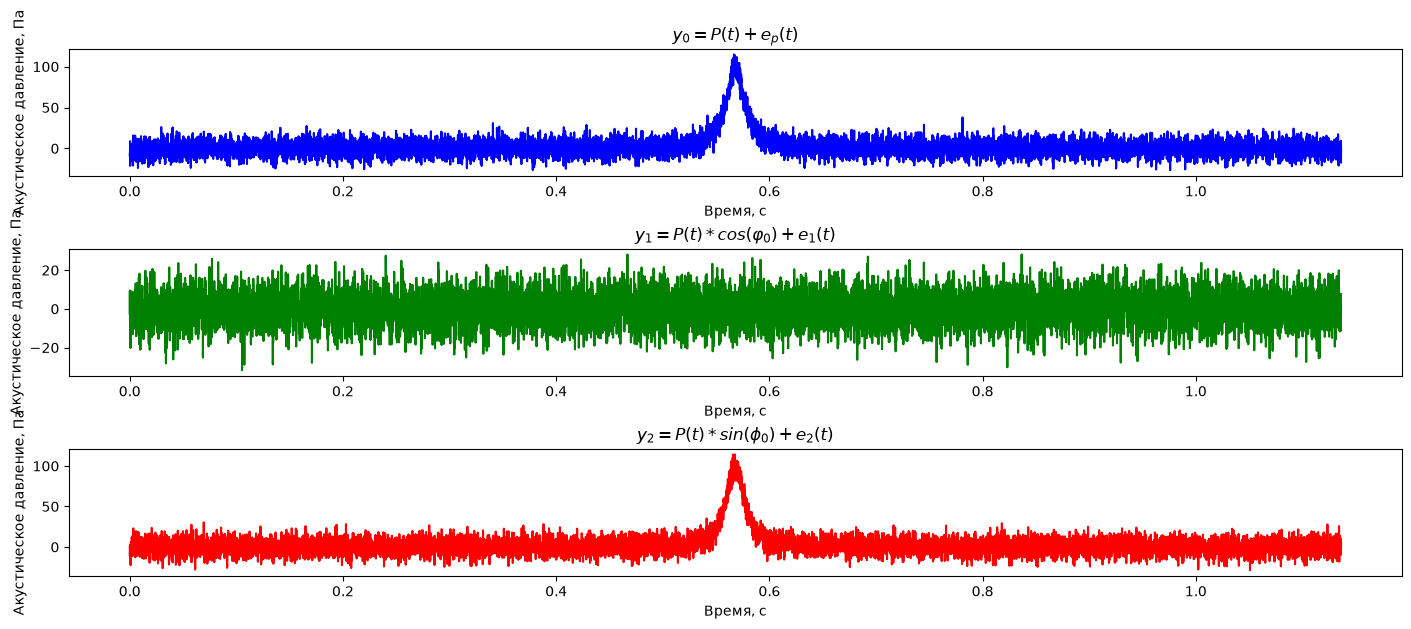

In [68]:
cfg.init_rng()
signals = get_avp_signals(values_signal, q, en_signal)

fig, axs = plt.subplots(3,1, figsize = (14,6), constrained_layout = True)
colors = ("blue", "green", "red")
titles = (rf"$y_0 = P(t) + e_p(t)$", rf"$y_1 = P(t)*cos(\varphi_0) + e_1(t)$" , rf"$y_2 = P(t)*sin(\phi_0) + e_2(t)$" )

for idx, (y, title, color) in enumerate(zip(signals.values(),titles,colors)):
    axs[idx].plot(cfg.time_vector,y, color = color)
    axs[idx].set_xlabel("Время, с")
    axs[idx].set_ylabel("Акустическое давление, Па")
    axs[idx].set_title(title)
    

In [69]:
channel_matrix = get_channel_matrix(q, tau_array, get_impulse_signal)
W = get_covariation_matrix(channel_matrix, cfg.N)
dir_matrix = get_direction_matrix(cfg.PHI_VALUES, cfg.M)
E_bar = get_barlet_values(W,dir_matrix)

$$
\mathbf a(\varphi) =
\begin{bmatrix}
1 \\
\cos\varphi \\
\sin\varphi \\
\vdots \\
1 \\
\cos\varphi \\
\sin\varphi
\end{bmatrix}_{3M \times 1}.
$$

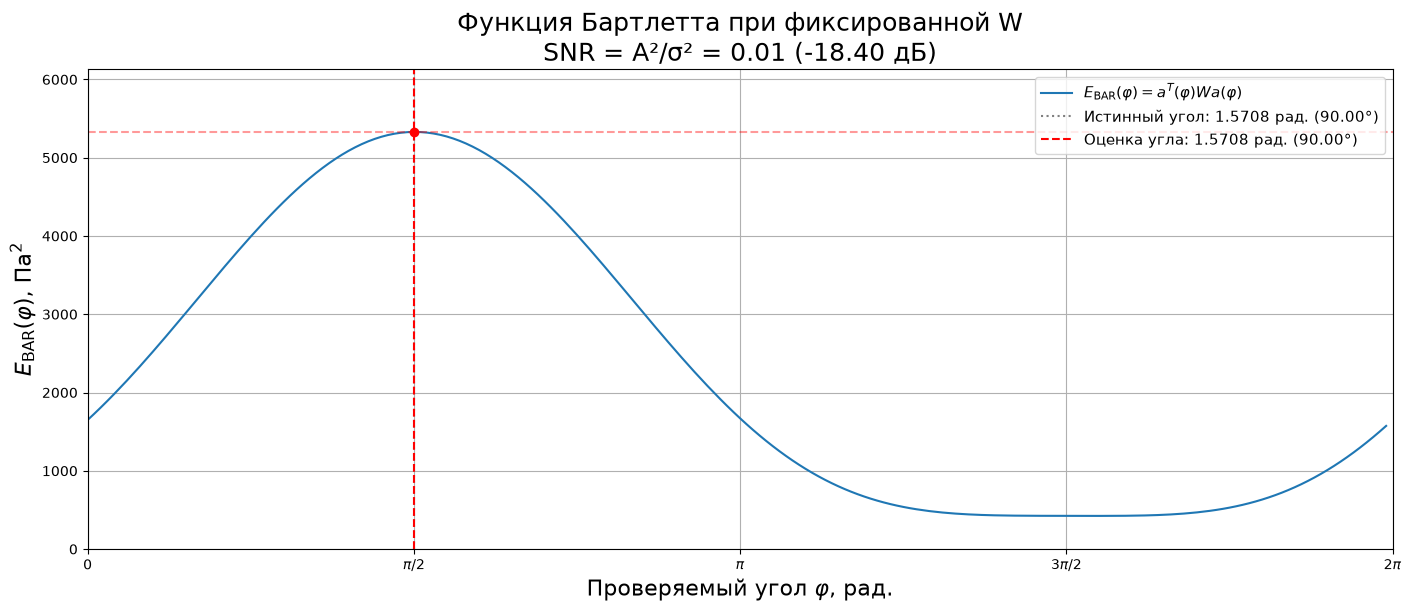

In [70]:
# SNR convention from info.md: amplitude squared / noise variance.
sigma_noise = noise_level
phi_0 = cfg.TARGET_PHI
phi_vector = cfg.PHI_VALUES
est_phi = get_est_phi(phi_vector, E_bar)
E_max = max(E_bar)
A = cfg.A

snr_ratio = np.inf if sigma_noise == 0 else A**2 / sigma_noise**2
snr_text = "∞ (без шума)" if np.isinf(snr_ratio) else f"{snr_ratio:.2f} ({10 * np.log10(snr_ratio):.2f} дБ)"
fig, ax = plt.subplots(figsize=(14, 6), constrained_layout=True)
ax.plot(phi_vector, E_bar, label=r"$E_{\mathrm{BAR}}(\varphi)=a^T(\varphi)W a(\varphi)$")
ax.axvline(phi_0, color="gray", linestyle=":", label=f"Истинный угол: {phi_0:.4f} рад. ({np.degrees(phi_0):.2f}°)")
ax.axvline(est_phi, color="red", linestyle="--", label=f"Оценка угла: {est_phi:.4f} рад. ({np.degrees(est_phi):.2f}°)")
ax.scatter(est_phi, E_max, color="red", zorder=3)
ax.axhline(E_max, color="red", linestyle="--", alpha=0.4)
ax.set_title(f"Функция Бартлетта при фиксированной W\nSNR = A²/σ² = {snr_text}", fontsize=18)
ax.set_xlabel(r"Проверяемый угол $\varphi$, рад.", fontsize=16)
ax.set_ylabel(r"$E_{\mathrm{BAR}}(\varphi)$, $\mathrm{Па}^2$", fontsize=16)
ax.set_xticks(
    [0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi],
    ["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"],
)
ax.set_xlim(0, 2 * np.pi)
ax.set_ylim(0, 1.15 * max(E_bar))
ax.legend(loc="upper right", fontsize=11)
ax.grid(True)
plt.show()


In [71]:
def score_phi(phi_vector, values):
    return phi_vector[np.argmax(values)]


score = score_phi(phi_vector, E_bar)
score*(180/np.pi)

np.float64(90.00000000000001)